# Tutorial 04: Unsupervised Digit Recognition with STDP (Diehl & Cook 2015)

Diehl & Cook (2015) showed that a two-layer spiking network learns to recognise handwritten
digits with no labels during training. 784 Poisson inputs, one per MNIST pixel, drive a layer
of excitatory neurons through plastic synapses. Every excitatory neuron excites one inhibitory
partner, which inhibits all the *other* excitatory neurons, so a few neurons win each digit.
STDP pulls the winners' input weights toward the digit they won, and an adaptive threshold,
raised by every spike, keeps any one neuron from winning everything. Each neuron ends up a
prototype of one way of writing one digit. Labels are needed only afterwards, to name the
neurons: each one is assigned the class it responds to most.

This notebook builds that network with SuperNeuroABM, following the authors' released Brian 1
code tick for tick: 0.5 ms ticks, each digit shown for 350 ms followed by 150 ms of rest, the
authors' parameters, their weight normalisation, retry rule and readout. With 100 excitatory
neurons it trains on the first 3000 MNIST training digits, labels the neurons with
1000 digits and tests on 1000 test digits: about 8 minutes on a laptop GPU
(RTX 3000 Ada), every phase timed. The full protocol is the same code with larger numbers and
takes hours, so the last section loads and draws the weights that a full-length run learned:
the paper's 40,000 training digits for now, and 180,000, as many as the authors' code trains on,
once that run is done.

As in tutorials 01 and 03, every component is ours: the soma, the synapse and the learning rule
are three CUDA kernels in `customized_step_functions/`, registered on the model at runtime,
even where a built-in kernel could have been configured to do part of the job. Each can be
changed without touching the installed `superneuroabm` package.

| file | what it is |
|---|---|
| `customized_step_functions/user_customized_diehl_cook_soma.py` | both neuron types: a conductance-based leaky integrate-and-fire neuron, with the adaptive threshold for the excitatory one |
| `customized_step_functions/user_customized_diehl_cook_synapse.py` | every synapse: delivers its weight into the excitatory or the inhibitory conductance of its target |
| `customized_step_functions/user_customized_diehl_cook_stdp.py` | the triplet STDP rule the authors' code runs |
| `diehl_cook_config.yaml` | the parameters of all three, with the authors' values |
| `diehl_cook_mnist.py` | MNIST (downloaded once, 11 MB), the Poisson encoding and the readout |
| `pretrained/diehl_cook_n100_40k/` | weights, thresholds and labels learned by the 40,000-digit run of the paper's protocol, with its accuracy (`result.json`); `diehl_cook_n100_180k/` joins it when the 180,000-digit run is done |

Reference: Diehl PU, Cook M (2015). *Unsupervised learning of digit recognition using
spike-timing-dependent plasticity.* Frontiers in Computational Neuroscience 9:99. The authors'
code: [peter-u-diehl/stdp-mnist](https://github.com/peter-u-diehl/stdp-mnist).

## Imports and the protocol

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import cupy as cp
import matplotlib.pyplot as plt

from superneuroabm.model import NeuromorphicModel
from sagesim.agent_index import rows_of

# Three tutorial-owned CUDA kernels, defined in customized_step_functions/ and
# registered at runtime. None of them lives inside the superneuroabm package.
STEP_FUNC_DIR = Path("customized_step_functions").resolve()
sys.path.insert(0, str(STEP_FUNC_DIR))   # import them by module name, as the generated kernel does
from user_customized_diehl_cook_soma import user_customized_diehl_cook_soma
from user_customized_diehl_cook_synapse import user_customized_diehl_cook_synapse
from user_customized_diehl_cook_stdp import user_customized_diehl_cook_stdp
import diehl_cook_mnist as mnist

N_EXC = 100                  # excitatory neurons (and as many inhibitory ones)
N_TRAIN = 3000              # training digits; the paper's 100-neuron protocol uses 40,000
N_LABEL = 1000              # training digits shown again, frozen, to label the neurons
N_TEST = 1000               # test digits
SEED = 0

DT = mnist.DT                       # 0.5 ms
PRESENT_TICKS = mnist.PRESENT_TICKS # 350 ms of input per digit
REST_TICKS = 300                    # 150 ms of rest, so the network relaxes between digits
PERIOD = PRESENT_TICKS + REST_TICKS
MAX_DELAY_TICKS = 19                # input -> exc delays are uniform in [0, 10 ms)
WEIGHT_SUM = 78.0                   # each neuron's 784 input weights are rescaled to sum to this
TC_THETA = 1e4                      # adaptive-threshold decay time constant, 1e7 ms
THETA_DECAY_PER_DIGIT = (1.0 - DT / TC_THETA) ** PERIOD
START_INTENSITY = 2.0               # a white pixel fires at 255 / 8 * 2 = 63.75 Hz
MIN_SPIKES = 5                      # fewer excitatory spikes than this: show the digit again, brighter
MAX_INTENSITY = 8.0

## The input

The data are the 60,000 training and 10,000 test images of MNIST, 28 x 28 pixels of 0..255.
`diehl_cook_mnist.load_mnist` downloads them once into `data/mnist/`.

Each digit is shown as Poisson spike trains, as in the authors' code: pixel `p` fires at
`p / 8 * intensity` Hz on every tick of the 350 ms presentation, so at the starting intensity of
2 a white pixel fires at 63.75 Hz and a black one never. If the excitatory layer answers with
fewer than 5 spikes, the digit is shown again with the intensity raised by 1. Digits are shown in
dataset order, as the authors do.

train (60000, 784), test (10000, 784); first labels [5, 0, 4, 1, 9, 2, 1, 3, 1, 4]


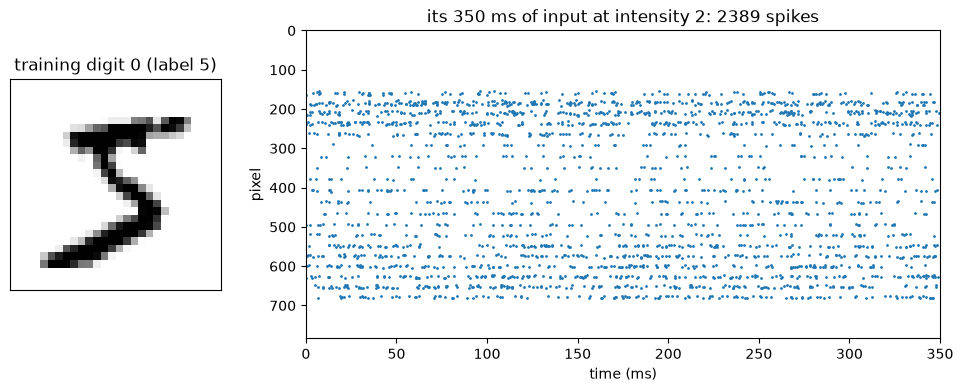

In [2]:
train_x, train_y = mnist.load_mnist("train")
test_x, test_y = mnist.load_mnist("test")
print(f"train {train_x.shape}, test {test_x.shape}; first labels {train_y[:10].tolist()}")

input_rng = np.random.default_rng(SEED)        # draws every input spike of the run
pix, tick = mnist.poisson_input(train_x[0], START_INTENSITY, np.random.default_rng(1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 3]})
ax1.imshow(train_x[0].reshape(28, 28), cmap="gray_r")
ax1.set(title=f"training digit 0 (label {train_y[0]})", xticks=[], yticks=[])
ax2.scatter(tick * DT * 1e3, pix, s=1)
ax2.set(xlim=(0, PRESENT_TICKS * DT * 1e3), ylim=(784, 0), xlabel="time (ms)", ylabel="pixel",
        title=f"its 350 ms of input at intensity {START_INTENSITY:g}: {len(pix)} spikes")
plt.show()

## The network: three components of our own

| component | file | breed / config in `diehl_cook_config.yaml` |
|---|---|---|
| excitatory neuron (x 100) | `user_customized_diehl_cook_soma.py` | `user_customized_diehl_cook_soma` / `diehl_cook_exc` |
| inhibitory neuron (x 100) | same kernel | `user_customized_diehl_cook_soma` / `diehl_cook_inh` |
| input -> excitatory (x 78,400), plastic | `user_customized_diehl_cook_synapse.py` | `user_customized_diehl_cook_synapse` / `diehl_cook_input` |
| excitatory -> its inhibitory partner (x 100) | same kernel | `user_customized_diehl_cook_synapse` / `diehl_cook_exc_to_inh` |
| inhibitory -> every other excitatory (x 9,900) | same kernel | `user_customized_diehl_cook_synapse` / `diehl_cook_inh_to_exc` |
| learning rule, on the input synapses | `user_customized_diehl_cook_stdp.py` | `user_customized_diehl_cook_stdp` / `diehl_cook_triplet` |

**The neuron** is conductance-based, unlike the built-in somas, which add their input as a
current: an excitatory conductance `ge` pulls the membrane toward 0 mV and an inhibitory one `gi`
toward `e_inh` = -100 mV, so inhibition gets stronger the more depolarised the cell is. The two
conductances live on the soma, in two inbox channels with their own time constants (1 and 2 ms).
The excitatory neurons have the adaptive threshold `theta`: every spike raises it by 0.05 mV and
it decays over 10^7 ms, practically never within a run. A neuron that wins often becomes harder to
drive, and the others get their turn. Refractoriness follows Brian 1 exactly, which treats the two
populations differently: the excitatory membrane keeps integrating during its 5 ms refractory
period, the inhibitory one is clamped.

**The synapse** delivers its weight into channel 0 (excitatory) or 1 (inhibitory) of its target
soma's inbox when its presynaptic neuron fires. An inhibitory synapse has a positive weight; the
driving force gives it its sign. Each of the 78,400 input synapses has its own fixed delay, drawn
uniformly from 0 to 10 ms, as in the authors' code: the notebook injects each pixel's spikes on
every synapse of that pixel, shifted by that synapse's delay.

**The learning rule** is the triplet STDP of the authors' code: a presynaptic spike depresses the
weight a little in proportion to a fast postsynaptic trace; a postsynaptic spike potentiates it in
proportion to the presynaptic trace times a slow postsynaptic trace. The weights are clipped to
[0, 1], and before every digit each neuron's 784 input weights are rescaled to sum to 78, so
learning redistributes the weight a neuron has rather than adding to it.

**Timing.** In the authors' code a spike at tick `t` reaches the target's conductance at `t` and its
membrane at `t + 1`, so the excitatory -> inhibitory -> excitatory loop takes 1 ms. Our synapse
therefore reads its presynaptic neuron's spike of the *same* tick, which the framework allows
because somas run before synapses within a tick. That needs every synapse stepped on every tick,
`synapse_stepping="clocked"`: in the default event stepping a synapse runs on the tick *after* its
presynaptic neuron fired, which would double the loop to 2 ms. (Tutorial 03's synapses keep no
timing of their own and use event stepping.)

In [3]:
CONFIG_DIR = Path(".").resolve()

SOMA_BREED = "user_customized_diehl_cook_soma"
SYNAPSE_BREED = "user_customized_diehl_cook_synapse"
STDP_RULE = "user_customized_diehl_cook_stdp"     # the learning_rule: block in the YAML

model = NeuromorphicModel(
    user_config=CONFIG_DIR / "diehl_cook_config.yaml",
    enable_internal_states_tracking=False,         # 1000 ticks x 88,600 agents per digit: no history
    synapse_stepping="clocked",                    # every synapse every tick (see above)
)
model.set_global_property_value("dt", DT)          # 0.5 ms ticks

# All three registrations must happen before setup(), which generates the fused kernel.
model.register_soma_type(
    name=SOMA_BREED,
    step_func=user_customized_diehl_cook_soma,
    step_func_path=STEP_FUNC_DIR / "user_customized_diehl_cook_soma.py",
)
model.register_synapse_type(
    name=SYNAPSE_BREED,
    step_func=user_customized_diehl_cook_synapse,
    step_func_path=STEP_FUNC_DIR / "user_customized_diehl_cook_synapse.py",
)
# The six built-in rules occupy ids 0-5, so ours gets 6; a synapse selects it through
# its stdp_type learning hyperparameter.
STDP_RULE_ID = model.register_learning_rule(
    step_func=user_customized_diehl_cook_stdp,
    step_func_path=STEP_FUNC_DIR / "user_customized_diehl_cook_stdp.py",
)
print(f"registered {SOMA_BREED!r}, {SYNAPSE_BREED!r} and {STDP_RULE!r} (learning rule id {STDP_RULE_ID})")

registered 'user_customized_diehl_cook_soma', 'user_customized_diehl_cook_synapse' and 'user_customized_diehl_cook_stdp' (learning rule id 6)


In [4]:
t0 = time.time()
rng = np.random.default_rng(SEED)

exc = [model.create_soma(breed=SOMA_BREED, config_name="diehl_cook_exc") for _ in range(N_EXC)]
inh = [model.create_soma(breed=SOMA_BREED, config_name="diehl_cook_inh") for _ in range(N_EXC)]

# The authors' initial weights, (uniform + 0.01) * 0.3, rescaled so each neuron's column sums
# to 78; and one delay per input synapse, uniform over 0..19 ticks (0 to 10 ms).
initial_weights = (rng.random((784, N_EXC)) + 0.01) * 0.3
initial_weights *= WEIGHT_SUM / initial_weights.sum(axis=0, keepdims=True)
delays = rng.integers(0, MAX_DELAY_TICKS + 1, size=(784, N_EXC))

# Input synapse [i, j] carries pixel i to excitatory neuron j. pre_soma_id=-1 marks an external
# input. learning_rule= names the YAML block of the STDP parameters; stdp_type selects the kernel.
input_synapses = np.array([[
    model.create_synapse(
        breed=SYNAPSE_BREED, pre_soma_id=-1, post_soma_id=exc[j],
        config_name="diehl_cook_input",
        learning_rule=STDP_RULE, learning_rule_config="diehl_cook_triplet",
        overrides={"hyperparameters": {"weight": float(initial_weights[i, j])},
                   "learning_hyperparameters": {"stdp_type": float(STDP_RULE_ID)}},
    ) for j in range(N_EXC)] for i in range(784)], dtype=np.int64)

# Each excitatory neuron drives its inhibitory partner, which inhibits all the other ones.
for e, i in zip(exc, inh):
    model.create_synapse(breed=SYNAPSE_BREED, pre_soma_id=e, post_soma_id=i,
                         config_name="diehl_cook_exc_to_inh")
for k, i in enumerate(inh):
    for j, e in enumerate(exc):
        if j != k:
            model.create_synapse(breed=SYNAPSE_BREED, pre_soma_id=i, post_soma_id=e,
                                 config_name="diehl_cook_inh_to_exc")

n_synapses = input_synapses.size + N_EXC + N_EXC * (N_EXC - 1)
build_seconds = time.time() - t0
print(f"{len(exc) + len(inh)} somas and {n_synapses:,} synapses built in {build_seconds:.1f} s")
# Key order in the YAML is the index order the kernels read; a reordered block shows up here.
print("exc neuron:", model.get_hyperparameters(exc[0]))
print("inh neuron:", model.get_hyperparameters(inh[0]))
print("input synapse:", model.get_hyperparameters(int(input_synapses[0, 0])))
print("learning:", model.get_learning_hyperparameters(int(input_synapses[0, 0])))

200 somas and 88,400 synapses built in 1.3 s
exc neuron: {'v_rest': -65.0, 'v_reset': -65.0, 'v_thresh': -52.0, 'tau_v': 0.1, 'e_inh': -100.0, 'theta_plus': 0.05, 'offset': 20.0, 'lockout_ticks': 9.0, 'hold_ticks': 0.0, 'tau_syn_0': 0.001, 'tau_syn_1': 0.002}
inh neuron: {'v_rest': -60.0, 'v_reset': -45.0, 'v_thresh': -40.0, 'tau_v': 0.01, 'e_inh': -85.0, 'theta_plus': 0.0, 'offset': 0.0, 'lockout_ticks': 3.0, 'hold_ticks': 4.0, 'tau_syn_0': 0.001, 'tau_syn_1': 0.002}
input synapse: {'weight': 0.12755358891164018, 'synaptic_delay': 1.0, 'channel': 0.0}
learning: {'stdp_type': 6.0, 'tc_pre': 0.02, 'tc_post_1': 0.02, 'tc_post_2': 0.04, 'nu_pre': 0.0001, 'nu_post': 0.01, 'wmax': 1.0, 'wmin': 0.0}


## Setup, and the live device tensors

`setup()` generates and compiles the fused kernel. A first, silent period then lets the
membranes relax from their initial `v_rest - 40 mV` and allocates the device buffers.

Between two digits the authors' code does three things to the network that are not spikes:
it rescales each neuron's 784 input weights to sum to 78, it decays `theta`, and it replaces the
input. All three happen 40,000 times in the full protocol and touch up to 78,400 synapses, so
they are done on the device, on the model's live property tensors: one row per agent, columns
in the YAML key order (`hyperparameters[:, 0]` is the weight, `internal_states[:, 1]` is
`theta`). A host-side write such as `set_hyperparameters` would also be correct, since the model
downloads the device state before it and refreshes the device after it, but at a host round
trip per digit. The new input goes in with `set_input_events`, which takes the synapses' buffer
rows and compiles the event list on the device.

The few writes that happen once, when training ends, use the ordinary API below.

In [5]:
t0 = time.time()
model.setup()
model.set_recorded_somas(exc)          # only the excitatory layer's spikes are read back
model.simulate(ticks=PERIOD)           # one silent period: relax, and build the device buffers
model.clear_input_spikes()
setup_seconds = time.time() - t0
print(f"setup and first period: {setup_seconds:.1f} s")

buf = model._gpu_buffers
input_rows = cp.asarray(rows_of(buf.agent_id_to_index, input_synapses)).reshape(784, N_EXC)
exc_rows = cp.asarray(rows_of(buf.agent_id_to_index, exc))
delays_gpu = cp.asarray(delays)
THETA = 1                              # index of theta in the soma's internal_states


def device(prop):
    '''The live device tensor of one property, one row per agent.'''
    return model._gpu_buffers.property_tensors[model._agent_factory._property_name_2_index[prop]]


def input_weights():
    '''[784, N_EXC] input weights, on the device.'''
    return device("hyperparameters")[input_rows, 0]


def normalize_weights():
    '''Rescale each neuron's input column to sum to WEIGHT_SUM (factors in float64, as Brian).'''
    w = input_weights().astype(cp.float64)
    device("hyperparameters")[input_rows, 0] = w * (WEIGHT_SUM / w.sum(axis=0))


def thetas():
    return device("internal_states")[exc_rows, THETA].get()


def decay_theta():
    '''One digit's worth of dtheta/dt = -theta / tc_theta. The per-tick factor 1 - 5e-8 is not
    representable in float32, so it is applied once per digit.'''
    st = device("internal_states")
    st[exc_rows, THETA] = st[exc_rows, THETA] * THETA_DECAY_PER_DIGIT

setup and first period: 3.9 s


## One presentation

`present` runs one digit the way the authors' loop does: rescale the weights (training only),
inject the input, run 1000 ticks (350 ms of input and 150 ms of rest) in one `simulate()` call,
count each excitatory neuron's spikes during the input, decay `theta` (training only).
`show_digit` adds the retry rule.

Two details. The clock is set back to tick 0 before every digit: the kernels then see the tick
*within* the presentation, and every tick stored in a float32 tensor stays small and exact (a
float32 counts integers exactly only up to 2^24 ticks, about 16,800 digits). The framework
notices the rewind and discards the previous digit's delivered spikes. And the 784 pixel trains
become about half a million events: one per pixel spike *per synapse of that pixel*, each shifted
by that synapse's delay. They are built on the device from the `(pixel, tick)` pairs.

In [6]:
def present(pix, tick, learn):
    '''One digit: returns each excitatory neuron's spike count during the 350 ms of input.'''
    if learn:
        normalize_weights()
    model.tick = 0
    pix, tick = cp.asarray(pix), cp.asarray(tick)
    model.set_input_events(input_rows[pix].ravel(),                        # (spikes x N_EXC,)
                           (tick[:, None] + delays_gpu[pix]).ravel())      # delayed per synapse
    model.simulate(ticks=PERIOD)
    spikes = model.get_all_spike_times()           # ticks of the call that just ran
    counts = np.array([sum(1 for t in spikes.get(s, ()) if t < PRESENT_TICKS) for s in exc])
    if learn:
        decay_theta()
    return counts


def show_digit(image, learn):
    '''present() with the retry rule: brighter until the layer answers with MIN_SPIKES spikes.'''
    intensity, retries = START_INTENSITY, 0
    while True:
        counts = present(*mnist.poisson_input(image, intensity, input_rng), learn)
        if counts.sum() >= MIN_SPIKES or intensity >= MAX_INTENSITY:
            return counts, retries
        intensity += 1.0
        retries += 1


def run_phase(images, learn, name, log_every):
    '''Show every image once. Returns the [len(images), N_EXC] spike counts, and the retries and
    the wall time (s) of every digit.'''
    responses = np.zeros((len(images), N_EXC), dtype=np.int32)
    retries = np.zeros(len(images), dtype=np.int32)
    seconds = np.zeros(len(images))
    t0 = time.time()
    for k, image in enumerate(images):
        t_digit = time.time()
        responses[k], retries[k] = show_digit(image, learn)
        seconds[k] = time.time() - t_digit
        if (k + 1) % log_every == 0 or k + 1 == len(images):
            recent = slice(max(0, k + 1 - log_every), k + 1)
            th = thetas()
            print(f"{name} {k + 1:5d}/{len(images)}   {(k + 1) / (time.time() - t0):4.1f} digits/s   "
                  f"spikes/digit {responses[recent].sum(axis=1).mean():4.1f}   "
                  f"retries {retries[:k + 1].sum():4d}   theta {th.mean():.2f} +- {th.std():.2f} mV")
    print(f"{name}: {len(images)} digits in {time.time() - t0:.1f} s")
    return responses, retries, seconds

## Training

STDP on, `theta` adapting, the weights rescaled before every digit. Nothing tells the network
which digit it sees. Watch `theta` climb: the neurons that win most get the highest thresholds.

In [7]:
train_responses, train_retries, train_time = run_phase(train_x[:N_TRAIN], learn=True, name="train",
                                                       log_every=500)
learned_weights = input_weights().get()
learned_theta = thetas()
print(f"weights: min {learned_weights.min():.4f}, max {learned_weights.max():.4f}, "
      f"column sums {learned_weights.sum(axis=0).mean():.1f}")

train   500/3000    8.5 digits/s   spikes/digit 10.2   retries   50   theta 22.09 +- 4.33 mV


train  1000/3000    8.6 digits/s   spikes/digit 10.8   retries   94   theta 24.25 +- 5.74 mV


train  1500/3000    8.5 digits/s   spikes/digit 11.3   retries  149   theta 26.48 +- 6.56 mV


train  2000/3000    8.4 digits/s   spikes/digit 10.2   retries  224   theta 28.39 +- 6.74 mV


train  2500/3000    8.4 digits/s   spikes/digit 10.0   retries  301   theta 30.19 +- 6.77 mV


train  3000/3000    8.2 digits/s   spikes/digit  9.6   retries  420   theta 31.83 +- 6.83 mV
train: 3000 digits in 363.8 s
weights: min 0.0000, max 0.4726, column sums 78.0


## Labelling and testing

The authors' test mode: no STDP, `theta` frozen (no growth, no decay), no rescaling. `model.eval()`
switches every plastic synapse's rule off and setting `theta_plus` to 0 stops the thresholds
from growing. Both are ordinary host-side writes; the model syncs the device first and refreshes
it in place afterwards, so nothing learned is lost.

Then each excitatory neuron is labelled with the class it responds to most, on average, over the
first 1000 training digits shown again; a test digit is classified as the class whose
neurons respond most, on average.

In [8]:
model.eval()                                            # STDP off on every plastic synapse
model.set_hyperparameters(exc, {"theta_plus": 0.0})     # theta frozen

label_responses, label_retries, label_time = run_phase(train_x[:N_LABEL], learn=False, name="label",
                                                      log_every=250)
assignments = mnist.assign_labels(label_responses, train_y[:N_LABEL])
print("neurons per class:", np.bincount(assignments, minlength=10).tolist())

test_responses, test_retries, test_time = run_phase(test_x[:N_TEST], learn=False, name="test",
                                                   log_every=250)
predicted = mnist.classify(test_responses, assignments)
accuracy = (predicted == test_y[:N_TEST]).mean()

assert np.array_equal(input_weights().get(), learned_weights), "weights changed while frozen"
assert np.array_equal(thetas(), learned_theta), "theta changed while frozen"
print(f"\naccuracy on {N_TEST} test digits: {accuracy * 100:.2f}%  (after {N_TRAIN} training digits)")

label   250/1000   23.6 digits/s   spikes/digit  8.7   retries   70   theta 31.83 +- 6.83 mV


label   500/1000   23.1 digits/s   spikes/digit  8.6   retries  154   theta 31.83 +- 6.83 mV


label   750/1000   23.0 digits/s   spikes/digit  8.7   retries  232   theta 31.83 +- 6.83 mV


label  1000/1000   23.4 digits/s   spikes/digit  9.2   retries  292   theta 31.83 +- 6.83 mV
label: 1000 digits in 42.8 s
neurons per class: [16, 7, 12, 12, 9, 7, 10, 10, 10, 7]


test   250/1000   21.0 digits/s   spikes/digit  8.6   retries  109   theta 31.83 +- 6.83 mV


test   500/1000   21.1 digits/s   spikes/digit  8.8   retries  212   theta 31.83 +- 6.83 mV


test   750/1000   21.6 digits/s   spikes/digit  8.6   retries  287   theta 31.83 +- 6.83 mV


test  1000/1000   21.7 digits/s   spikes/digit  8.7   retries  381   theta 31.83 +- 6.83 mV
test: 1000 digits in 46.2 s

accuracy on 1000 test digits: 68.00%  (after 3000 training digits)


## How long it took

Every phase of this run, timed on this machine. A presentation is one 500 ms showing of a digit;
a digit that needed retries took several. A training presentation costs about three times a
frozen one: the learning rule runs on all 78,400 input synapses on every tick.

Each digit was timed on its own. One takes well under a second even with retries, so a digit
that took longer than 30 s means the machine slept or stalled in the middle of it: that time is
reported separately, and `active` is the wall time without it.

In [9]:
STALL_S = 30.0
gpu = cp.cuda.runtime.getDeviceProperties(0)["name"].decode()
print(f"on {gpu}\n")
print(f"{'phase':21s} {'digits':>6s} {'presentations':>13s} {'wall s':>8s} {'active s':>8s} "
      f"{'ms/presentation':>15s} {'stalled digits':>14s}")
for name, s in (("build the network", build_seconds), ("setup + first period", setup_seconds)):
    print(f"{name:21s} {'':>6s} {'':>13s} {s:8.1f} {s:8.1f}")
total_wall, total_active = build_seconds + setup_seconds, build_seconds + setup_seconds
for name, retries, seconds in (("train", train_retries, train_time),
                               ("label", label_retries, label_time),
                               ("test", test_retries, test_time)):
    stalled = seconds > STALL_S
    active = seconds[~stalled].sum()
    presentations = len(seconds) + int(retries.sum())
    total_wall, total_active = total_wall + seconds.sum(), total_active + active
    print(f"{name:21s} {len(seconds):6d} {presentations:13d} {seconds.sum():8.1f} {active:8.1f} "
          f"{1e3 * active / presentations:15.1f} {int(stalled.sum()):14d}")
print(f"{'total':21s} {'':>6s} {'':>13s} {total_wall:8.1f} {total_active:8.1f}   "
      f"({total_active / 60:.1f} min active)")

on NVIDIA RTX 3000 Ada Generation Laptop GPU

phase                 digits presentations   wall s active s ms/presentation stalled digits
build the network                               1.3      1.3
setup + first period                            3.9      3.9
train                   3000          3420    363.8    363.8           106.4              0
label                   1000          1292     42.8     42.8            33.1              0
test                    1000          1381     46.2     46.2            33.4              0
total                                         458.0    458.0   (7.6 min active)


## What the neurons learned (the paper's figure 2A)

Each tile is one excitatory neuron's 784 input weights as a 28 x 28 image, labelled with the class
it was assigned. Most neurons have become a prototype of one digit; neurons that won few digits
are still blurred mixtures. Next to them, the thresholds: every neuron started at the same value,
and the spread is the homeostasis at work.

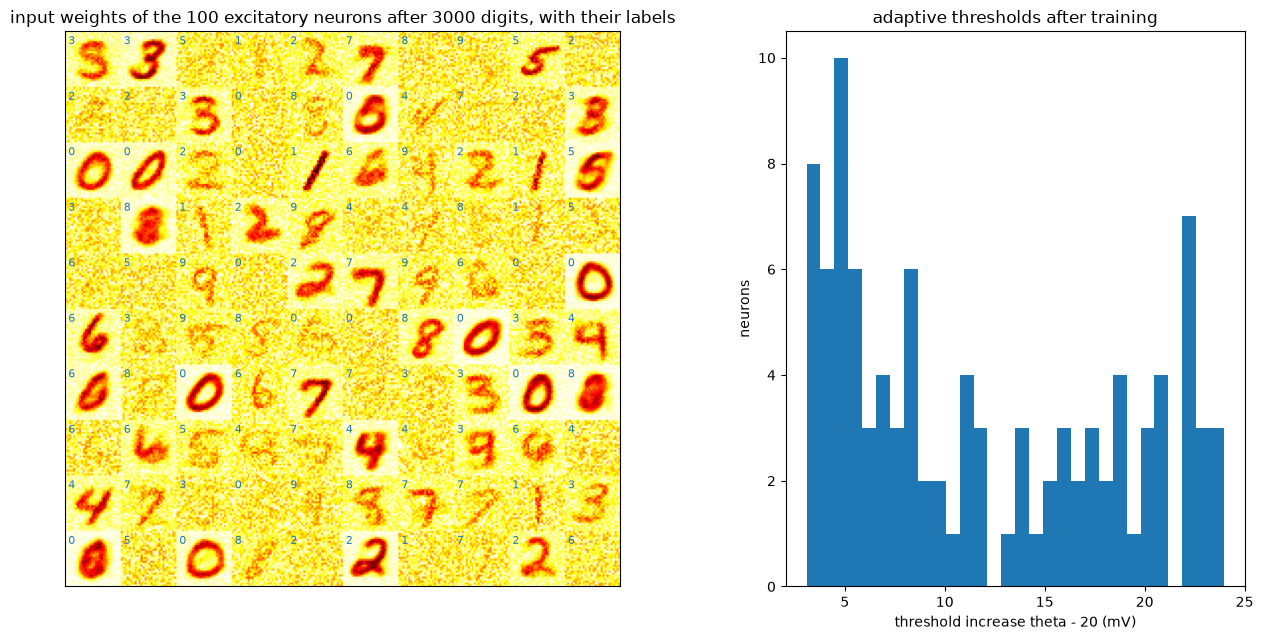

In [10]:
def plot_weights(weights, assignments, theta, title):
    '''The paper's figure 2A: each excitatory neuron's 784 input weights as a 28 x 28 tile,
    labelled with its class; next to it, the distribution of the adaptive thresholds.'''
    n = weights.shape[1]
    side = int(np.ceil(np.sqrt(n)))
    tiles = np.zeros((784, side * side), dtype=np.float32)
    tiles[:, :n] = weights
    grid = tiles.reshape(28, 28, side, side).transpose(2, 0, 3, 1).reshape(28 * side, 28 * side)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [2, 1]})
    ax1.imshow(grid, cmap="hot_r", vmin=0, vmax=weights.max())
    for k, label in enumerate(assignments):
        ax1.text(28 * (k % side) + 1, 28 * (k // side) + 6, str(label), color="tab:blue", fontsize=8)
    ax1.set(title=title, xticks=[], yticks=[])
    ax2.hist(theta - 20.0, bins=30)
    ax2.set(xlabel="threshold increase theta - 20 (mV)", ylabel="neurons",
            title="adaptive thresholds after training")
    plt.tight_layout()
    plt.show()


plot_weights(learned_weights, assignments, learned_theta,
             f"input weights of the {N_EXC} excitatory neurons after {N_TRAIN} digits, with their labels")

## How well it reads digits

The confusion matrix of the test digits, and the response of the frozen network to one of them:
a handful of excitatory neurons fire and the lateral inhibition silences the rest.

per-class accuracy: 0: 76% 1: 94% 2: 63% 3: 56% 4: 55% 5: 41% 6: 90% 7: 78% 8: 58% 9: 65%


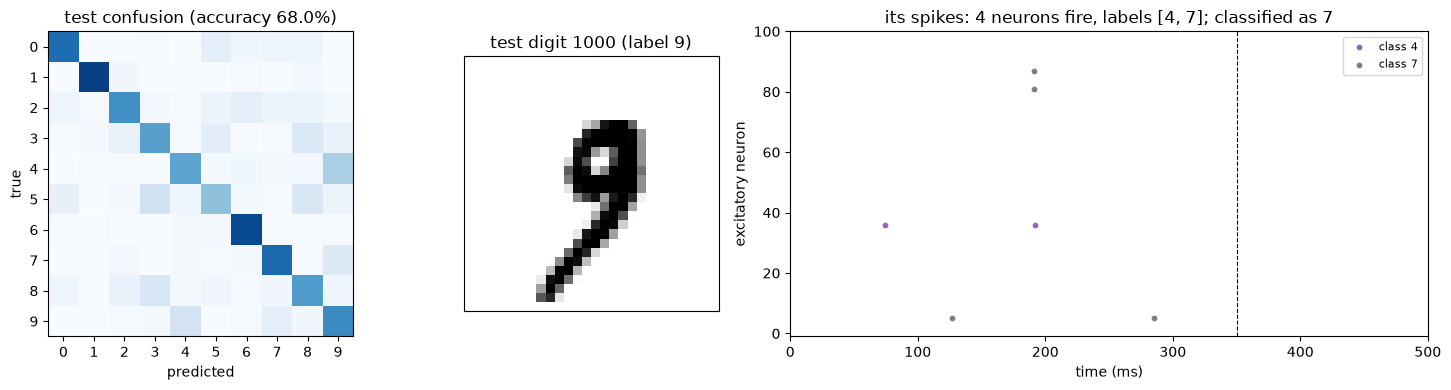

In [11]:
confusion = np.zeros((10, 10), dtype=np.int64)
np.add.at(confusion, (test_y[:N_TEST], predicted), 1)
row_sums = np.maximum(confusion.sum(axis=1, keepdims=True), 1)
per_class = confusion.diagonal() / row_sums[:, 0]
print("per-class accuracy:", " ".join(f"{c}: {a * 100:.0f}%" for c, a in enumerate(per_class)))

# One more test digit through the frozen network, to look at its spikes.
digit = N_TEST if N_TEST < len(test_x) else 0
counts, _ = show_digit(test_x[digit], learn=False)
spikes = model.get_all_spike_times()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1.2, 0.8, 2]})
ax1.imshow(confusion / row_sums, cmap="Blues", vmin=0, vmax=1)
ax1.set(xlabel="predicted", ylabel="true", xticks=range(10), yticks=range(10),
        title=f"test confusion (accuracy {accuracy * 100:.1f}%)")
ax2.imshow(test_x[digit].reshape(28, 28), cmap="gray_r")
ax2.set(title=f"test digit {digit} (label {test_y[digit]})", xticks=[], yticks=[])
for label in range(10):                      # one colour per assigned class
    rows = [(np.asarray(spikes.get(exc[n], []), dtype=float), n) for n in np.flatnonzero(assignments == label)]
    t = np.concatenate([r[0] for r in rows]) if rows else np.zeros(0)
    n = np.concatenate([np.full(len(r[0]), r[1]) for r in rows]) if rows else np.zeros(0)
    if len(t):
        ax3.scatter(t * DT * 1e3, n, s=10, color=f"C{label}", label=f"class {label}")
ax3.legend(loc="upper right", fontsize=8)
ax3.axvline(PRESENT_TICKS * DT * 1e3, color="k", ls="--", lw=0.8)
ax3.set(xlim=(0, PERIOD * DT * 1e3), ylim=(-1, N_EXC), xlabel="time (ms)", ylabel="excitatory neuron",
        title=f"its spikes: {int((counts > 0).sum())} neurons fire, labels "
              f"{sorted(set(assignments[counts > 0].tolist()))}; classified as "
              f"{mnist.classify(counts[None, :], assignments)[0]}")
plt.tight_layout()
plt.show()

## A full-length run: what tens of thousands of digits learn

The paper trains its 100-neuron network on 40,000 digits; the authors' code trains on three passes
over the 60,000 training digits, 180,000 presentations (`num_examples = 60000 * 3`). Training slows
down as it goes: as the thresholds rise, more digits need a brighter second showing, more than one
retry per digit after about 7,000 digits, so these runs take hours. They are made with the
replication in the `ns-applications` repository (`duplicates/diehl_cook_2015/run_experiment.py`),
whose 300-digit run this notebook's code reproduces bit for bit; it checkpoints every 5,000 digits
and can resume after an interruption.

`pretrained/` holds what such runs learned: weights, thresholds, labels and a `result.json`. The
cell below draws the longest run there. Until the 180,000-digit run is done, that is the
40,000-digit run of the paper's protocol, the 73.0 % of the next section (made in September 2026,
before the replication recorded timings). About half of its neurons have become clear prototypes
of a digit; the other half, 50 of 100, are still close to their random start.

pretrained/diehl_cook_n100_180k/ is not there yet: it comes from
  python run_experiment.py --n-exc 100 --n-train 180000 --n-label 10000 --n-test 10000 --tag full180k
in ns-applications/duplicates/diehl_cook_2015. Drawing pretrained/diehl_cook_n100_40k/ instead.

40,000 training digits, labels from 10,000 digits, tested on 10,000: accuracy 73.03%


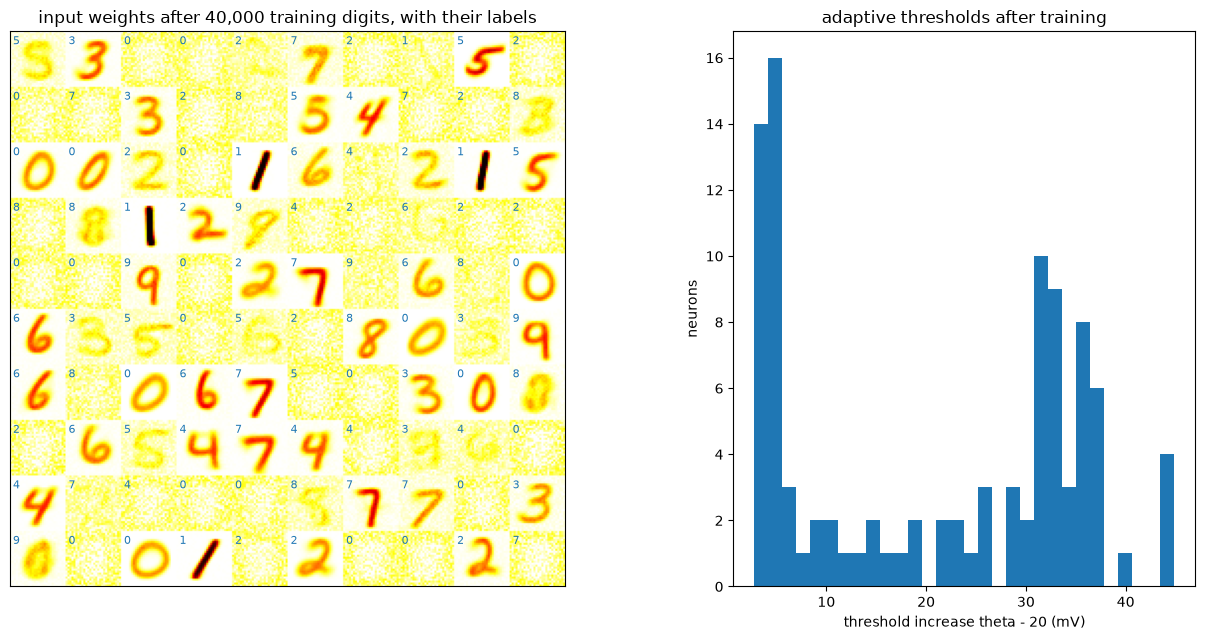

In [12]:
# The longest run in pretrained/: 180,000 digits once that run is done, 40,000 until then.
RUNS = [Path("pretrained/diehl_cook_n100_180k"), Path("pretrained/diehl_cook_n100_40k")]
if not (RUNS[0] / "weights.npy").exists():
    print(f"{RUNS[0]}/ is not there yet: it comes from\n  python run_experiment.py --n-exc 100 "
          f"--n-train 180000 --n-label 10000 --n-test 10000 --tag full180k\n"
          f"in ns-applications/duplicates/diehl_cook_2015. Drawing {RUNS[1]}/ instead.\n")
FULL_RUN = next(run for run in RUNS if (run / "weights.npy").exists())

full = json.loads((FULL_RUN / "result.json").read_text())
print(f"{full['n_train']:,} training digits, labels from {full['n_label']:,} digits, "
      f"tested on {full['n_test']:,}: accuracy {full['accuracy'] * 100:.2f}%")
if "timing" in full:
    timing, env = full["timing"], full["environment"]
    print(f"on {env['gpu']} (superneuroabm {env['superneuroabm_commit']}, sagesim {env['sagesim_commit']})"
          + (f", resumed at digit {full['resumed_from']}" if full["resumed_from"] else ""))
    for phase in ("train", "label", "test"):
        t = timing[phase]
        stalls = f", plus {t['stalled_s'] / 3600:.2f} h asleep or stalled" if t["stalled_digits"] else ""
        print(f"  {phase:5s} {t['digits']:7,d} digits, {t['presentations']:7,d} presentations: "
              f"{t['active_s'] / 3600:5.2f} h ({t['ms_per_presentation']:.0f} ms per presentation){stalls}")
    print(f"  total {timing['total_active_s'] / 3600:.2f} h")
plot_weights(np.load(FULL_RUN / "weights.npy"), np.load(FULL_RUN / "assignments.npy"),
             np.load(FULL_RUN / "theta.npy"),
             f"input weights after {full['n_train']:,} training digits, with their labels")

## The 40,000-digit protocol, against the authors' code

The paper's 100-neuron network is trained on 40,000 digits. Run through that protocol with seed 0 (40,000 training digits, labels from the first 10,000, all
10,000 test digits), this network and the authors' code, transcribed to Brian 2 with Brian 1's
semantics, give:

| | test accuracy |
|---|---|
| this network | 73.0 % |
| the authors' code, same protocol | 68.4 % |
| the paper, 100 neurons | 82.9 % |

One seed each, so the 4.6 points between the first two say little; what they do say is that this
network is not behind the code it follows. Over the first 10,000 training digits the two track
each other closely in spikes per digit, retries and threshold growth. The gap to the paper is
between the paper and the released code: the paper attributes its table to a power-law,
weight-dependent STDP variant that the released code does not include, and the released code's
default training is three passes over the training set, 180,000 presentations. The full
replication, with that comparison, lives in the `ns-applications` repository.

## Where to go from here

- **Change a component.** Each kernel's docstring is its full contract: the model, the parameter
  layout, the pinned slots and the registration call. The paper's text also describes a power-law,
  weight-dependent STDP rule; it goes into `user_customized_diehl_cook_stdp.py` (or a second rule
  registered next to it, selected per synapse by `stdp_type`), and the notebook does not change.
- **Take a mechanism out.** Set `theta_plus` to 0 in the excitatory block of the YAML and a few
  neurons win every digit; drop the `diehl_cook_inh_to_exc` synapses and nothing is winner-take-all.
- **More neurons.** The paper reports 87.0 % with 400 excitatory neurons and 95.0 % with 6,400,
  trained on more digits. `N_EXC` scales every array in this notebook.
- The custom-component contract is written up in `docs/CUSTOM_COMPONENTS.md`.